# 1 · Text as a graph

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/01_text_as_a_graph.ipynb)

A bag-of-words classifier looks at each document on its own. **TextGCN**
(Yao et al., 2019) takes a different view. The whole corpus becomes **one graph**,
whose nodes are the documents *and* the words, and a Graph Convolutional
Network learns by passing information along its edges.

Before training anything on a real dataset, we build that graph for **twelve
sentences** and open it up. By the end you will know what nodes and edges
Text4GCN creates, and why an unlabelled document can be classified just from
its position in the graph.

Runs on CPU in a few seconds.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | **Text as a graph** | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | Choosing a graph builder | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [12]:
import pickle
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy.sparse.csgraph import connected_components

from text4gcn import TextPipeline
from text4gcn.builder import Frequency
from text4gcn.datasets import save_corpus

## A tiny corpus

Two topics, *space* and *cooking*, with five labelled training sentences each.
The two **test** sentences have labels too, but the model will never see them:
we only use them to check the predictions at the end.

`save_corpus` writes the two files Text4GCN reads: `toy.txt`, with one document
per line, and `toy.meta`, with `<id>\t<train|test>\t<label>`.

In [13]:
corpus = [
    ("The rocket launched the satellite into orbit around the planet", "space", "train"),
    ("Astronauts on the space station watched the planet from orbit", "space", "train"),
    ("The telescope observed a distant galaxy and its bright stars", "space", "train"),
    ("A new rocket engine will carry astronauts to the moon", "space", "train"),
    ("The moon and the stars shine above the space station", "space", "train"),
    ("Bake the bread in a hot oven until the crust is golden", "cooking", "train"),
    ("Chop the garlic and onion before adding them to the pan", "cooking", "train"),
    ("The chef seasoned the soup with garlic salt and fresh herbs", "cooking", "train"),
    ("Knead the dough then let the bread rise before you bake it", "cooking", "train"),
    ("Fry the onion in olive oil and add fresh herbs to the pan", "cooking", "train"),
    ("The satellite telescope photographed stars in a distant galaxy", "space", "test"),
    ("The chef baked fresh bread and served it with soup", "cooking", "test"),
]

NAME, DATA_DIR = "toy", Path("data")
shutil.rmtree(DATA_DIR, ignore_errors=True)

texts, labels, splits = zip(*corpus)
save_corpus(DATA_DIR, NAME, texts=texts, labels=labels, splits=splits)
print((DATA_DIR / f"{NAME}.meta").read_text(encoding="utf-8"))

0	train	space
1	train	space
2	train	space
3	train	space
4	train	space
5	train	cooking
6	train	cooking
7	train	cooking
8	train	cooking
9	train	cooking
10	test	space
11	test	cooking



## Step 1: preprocess

`TextPipeline` lower-cases and tokenizes the text and removes stop words. It
also drops words seen fewer than `rare_count` times; with twelve sentences we
keep every word, so `rare_count=1`. It then shuffles the documents and saves the
vocabulary.

In [14]:
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, rare_count=1).execute()

[2026/10/16 11:06:53] [INFO] ======================================== NLTK Configuration ========================================
[2026/10/16 11:06:53] [INFO] Random seed (shuffle) = <1234>
[2026/10/16 11:06:53] [INFO] Validation ratio = <0.1>
[2026/10/16 11:06:53] [INFO] 
[2026/10/16 11:06:53] [INFO] ============================= CLEANED DATA: Removed rare & stop-words. =============================
[2026/10/16 11:06:53] [INFO] Start process: 1792145213.7531614
[2026/10/16 11:06:53] [INFO] Rare-Count = <1>
[2026/10/16 11:06:53] [INFO] Elapsed time is 0.001132 seconds.
[2026/10/16 11:06:53] [INFO] 
[2026/10/16 11:06:53] [INFO] ============================ SHUFFLED DATA: Corpus documents shuffled. =============================
[2026/10/16 11:06:53] [INFO] Start process: 1792145213.754362
[2026/10/16 11:06:53] [INFO] Elapsed time is 0.000473 seconds.
[2026/10/16 11:06:53] [INFO] 
[2026/10/16 11:06:53] [INFO] ======================= PREPARED WORDS: Vocabulary & word-vectors extracted. ===

[nltk_data] Downloading package stopwords to /home/vitor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/vitor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/vitor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [15]:
shuffled = DATA_DIR / f"{NAME}.shuffled"
vocab = (shuffled / f"{NAME}.vocab").read_text(encoding="utf-8").split()
meta = pd.read_csv(shuffled / f"{NAME}.meta", sep="\t", names=["id", "split", "label"])
docs = (shuffled / f"{NAME}.txt").read_text(encoding="utf-8").splitlines()

print(f"{len(vocab)} words:", " ".join(vocab))
meta.assign(cleaned_text=docs)

49 words: telescope observed distant galaxy bright stars knead dough let bread rise bake new rocket engine carry astronauts moon hot oven crust golden chop garlic onion adding pan shine space station fry olive oil add fresh herbs launched satellite orbit around planet watched chef seasoned soup salt baked served photographed


,id,split,label,cleaned_text
0,2,train,space,telescope observed distant galaxy bright stars
1,8,train,cooking,knead dough let bread rise bake
2,3,train,space,new rocket engine carry astronauts moon
3,5,train,cooking,bake bread hot oven crust golden
4,6,train,cooking,chop garlic onion adding pan
5,4,train,space,moon stars shine space station
6,9,train,cooking,fry onion olive oil add fresh herbs pan
7,0,train,space,rocket launched satellite orbit around planet
8,1,train,space,astronauts space station watched planet orbit
9,7,train,cooking,chef seasoned soup garlic salt fresh herbs


## Step 2: build the graph

`Frequency.tfidf()` builds the original TextGCN graph and saves its adjacency
matrix as a `scipy.sparse` file. It returns `GraphBuildStats`, whose `path`
field points to that file.

In [16]:
stats = Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf()
with open(stats.path, "rb") as f:
    adj = pickle.load(f)
stats

[2026/10/16 11:06:57] [INFO] =============== EXTRACTED ADJACENCY MATRIX: Heterogenous doc-word adjacency matrix. ================
[2026/10/16 11:06:57] [INFO] Start process: 1792145217.5876384
[2026/10/16 11:06:57] [INFO] Calculating PMI
[2026/10/16 11:06:57] [INFO] Calculating TF-IDF
[2026/10/16 11:06:57] [INFO] [INFO] (423, (423, 423)), shape=(61, 61)
[2026/10/16 11:06:57] [INFO] GraphBuildStats(frequency.tfidf: nodes=61, edges(nnz)=423, density=1.136791e-01, file=0.01 MiB)
[2026/10/16 11:06:57] [INFO] Elapsed time is 0.002249 seconds.
[2026/10/16 11:06:57] [INFO] 
[2026/10/16 11:06:57] [WARN] Directory:'data/log' already exists, not overwritten.


GraphBuildStats(n_nodes=61, n_edges=423, density=0.11367911851652782, file_bytes=5719, builder='frequency.tfidf', dataset_name='toy', path='data/toy.adjacency/ind.frequency.tfidf.toy.adj')

### Who is who

The adjacency matrix is square: **one row per node**. The nodes are in a fixed
order:

```
[ training documents | vocabulary words | test documents ]
```

In [17]:
train, test = meta[meta.split == "train"], meta[meta.split == "test"]
n_train, n_words = len(train), len(vocab)
assert adj.shape[0] == n_train + n_words + len(test)

nodes = pd.DataFrame({
    "kind": ["train doc"] * n_train + ["word"] * n_words + ["test doc"] * len(test),
    "name": [f"{lb} doc #{i}" for i, lb in zip(train.id, train.label)]
            + vocab
            + [f"? doc #{i}" for i in test.id],
})
nodes.groupby("kind", sort=False).size().rename("nodes")

kind
train doc    10
word         49
test doc      2
Name: nodes, dtype: int64

### Two kinds of edges

* **word–word**: two words that co-occur in the same sliding window more often
  than chance. The weight is their PMI (pointwise mutual information).
* **document–word**: a word that occurs in a document. The weight is its TF-IDF.

There are no document–document edges. Documents only meet **through shared
words**.

In [18]:
coo = adj.maximum(adj.T).tocoo()   # symmetric: every edge in both directions
edges = pd.DataFrame({"src": nodes.name.values[coo.row], "dst": nodes.name.values[coo.col],
                      "src_kind": nodes.kind.values[coo.row], "dst_kind": nodes.kind.values[coo.col],
                      "weight": coo.data})
edges = edges[coo.row < coo.col]   # each undirected edge once

word_word = edges[(edges.src_kind == "word") & (edges.dst_kind == "word")]
print(f"{len(word_word)} word-word edges; the strongest (PMI):")
# With twelve sentences many pairs tie: they co-occur only in their single sentence.
word_word.nlargest(8, "weight")[["src", "dst", "weight"]]

175 word-word edges; the strongest (PMI):


,src,dst,weight
74,observed,bright,2.484907
115,knead,dough,2.484907
116,knead,let,2.484907
118,knead,rise,2.484907
122,dough,let,2.484907
124,dough,rise,2.484907
130,let,rise,2.484907
168,new,engine,2.484907


In [19]:
doc_word = edges[(edges.src_kind != "word") ^ (edges.dst_kind != "word")]
print(f"{len(doc_word)} document-word edges; the words of the first test document (TF-IDF):")
first_test = nodes.name.iloc[n_train + n_words]
doc_word[(doc_word.src == first_test) | (doc_word.dst == first_test)] \
    .sort_values("weight", ascending=False)[["src", "dst", "weight"]]

73 document-word edges; the words of the first test document (TF-IDF):


,src,dst,weight
471,baked,? doc #11,2.484907
477,served,? doc #11,2.484907
458,soup,? doc #11,1.791759
440,chef,? doc #11,1.791759
363,fresh,? doc #11,1.386294
148,bread,? doc #11,1.386294


## Seeing the structure

We draw the graph with a small force-directed layout: edges pull their nodes
together, and all nodes push each other apart. Nothing here has been trained,
and labels are used only for the colours.

Each coloured circle is a document (`D7` is document 7), each beige circle a
word. A word grows with its number of edges, so the words shared by several
documents stand out. Test documents are drawn hollow: the model never sees
their label.

(np.float64(-1.2167087248754915),
 np.float64(3.546810447979204),
 np.float64(-0.7651073314055564),
 np.float64(0.6947227639194168))

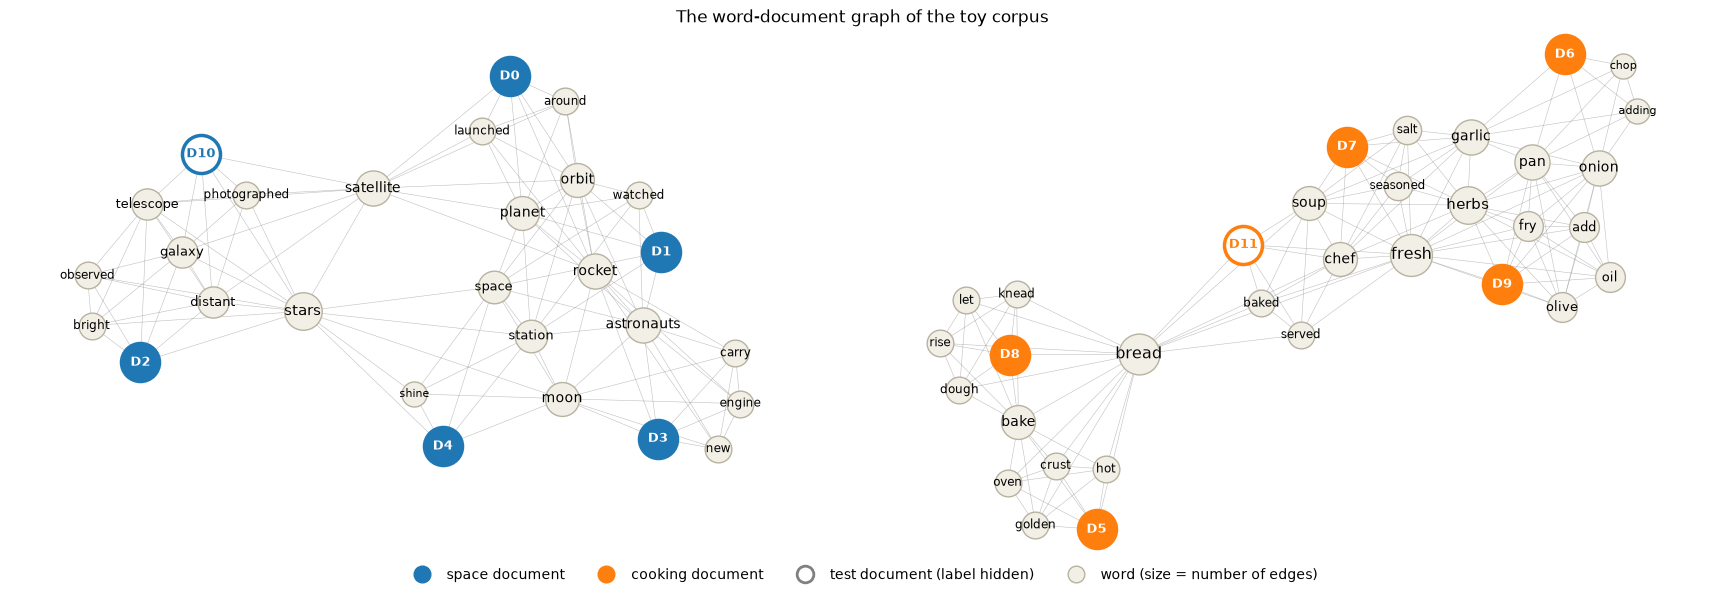

In [25]:
def force_layout(linked: np.ndarray, steps: int = 300, seed: int = 0) -> np.ndarray:
    """Fruchterman-Reingold: linked nodes attract, every pair of nodes repels."""
    xy = np.random.default_rng(seed).normal(size=(len(linked), 2))
    k = 1 / np.sqrt(len(linked))
    for step in np.linspace(0.1, 0.002, steps):
        delta = xy[:, None] - xy[None, :]
        dist = np.linalg.norm(delta, axis=-1) + 1e-9
        force = ((k**2 / dist**2 - linked * dist / k)[..., None] * delta).sum(axis=1)
        length = np.linalg.norm(force, axis=1, keepdims=True) + 1e-9
        xy += force / length * np.minimum(length, step)
    return xy

def remove_overlaps(xy: np.ndarray, radius: np.ndarray, steps: int = 300) -> np.ndarray:
    """Nudge apart every pair of nodes closer than the sum of their radii."""
    for _ in range(steps):
        delta = xy[:, None] - xy[None, :]
        dist = np.linalg.norm(delta, axis=-1) + np.eye(len(xy))
        overlap = np.clip(radius[:, None] + radius[None, :] - dist, 0, None) * (1 - np.eye(len(xy)))
        xy = xy + 0.25 * ((overlap / dist)[..., None] * delta).sum(axis=1)
    return xy

def node_label(k: int) -> str | None:
    """Topic of node k if it is a document (test labels are used only for colouring)."""
    kind = nodes.kind.iloc[k]
    return None if kind == "word" else meta.label.iloc[k if kind == "train doc" else k - n_words]

def draw_document(ax, k: int, xy, size: float = 750) -> None:
    """A document as a circle with its id: filled for training, hollow for test."""
    label, train_doc = node_label(k), nodes.kind.iloc[k] == "train doc"
    ax.scatter(*xy, s=size, zorder=2, linewidth=2.5, edgecolor=colors[label],
               color=colors[label] if train_doc else "white")
    ax.annotate("D" + nodes.name.iloc[k].split("#")[1], xy, ha="center", va="center", zorder=3,
                fontsize=9, weight="bold", color="white" if train_doc else colors[label])

dense = adj.toarray()
dense = np.maximum(dense, dense.T)                              # undirected
colors = {"space": "tab:blue", "cooking": "tab:orange"}
WORD_FILL, WORD_EDGE = "#f2efe6", "#b8b2a0"

degree = (dense > 0).sum(axis=1)                                # number of edges per node
size = np.where(nodes.kind == "word", 100 + 45 * degree, 750)   # marker area in points²
radius = np.sqrt(size) / 2 / 72 * 0.33 * 1.6                    # approx. in layout units, with room for labels

# Lay out each connected component on its own and place them side by side,
# so that two topics with no shared words do not squeeze each other.
n_parts, part = connected_components(dense > 0, directed=False)
xy = np.zeros((len(dense), 2))
for p in range(n_parts):
    members = np.flatnonzero(part == p)
    local = force_layout(dense[np.ix_(members, members)] > 0, seed=p)
    local = (local - local.mean(axis=0)) / np.abs(local - local.mean(axis=0)).max()
    xy[members] = remove_overlaps(local, radius[members]) + [2.4 * p, 0]

fig, ax = plt.subplots(figsize=(22, 22))
for i, j in zip(*np.nonzero(np.triu(dense))):
    ax.plot(*xy[[i, j]].T, color="gray", lw=0.4, alpha=0.5, zorder=0)
for k, name in enumerate(nodes.name):
    if nodes.kind.iloc[k] == "word":
        ax.scatter(*xy[k], s=size[k], color=WORD_FILL, edgecolor=WORD_EDGE, zorder=1)
        ax.annotate(name, xy[k], fontsize=7 + 0.25 * degree[k], ha="center", va="center", zorder=3)
    else:
        draw_document(ax, k, xy[k], size[k])

legend = [Line2D([], [], ls="", marker="o", ms=12, color=c, label=f"{topic} document")
          for topic, c in colors.items()]
legend += [Line2D([], [], ls="", marker="o", ms=12, mfc="white", mec="gray", mew=2,
                  label="test document (label hidden)"),
           Line2D([], [], ls="", marker="o", ms=12, mfc=WORD_FILL, mec=WORD_EDGE,
                  label="word (size = number of edges)")]
ax.legend(handles=legend, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
ax.set_title("The word-document graph of the toy corpus")
ax.set_aspect("equal")
ax.axis("off")

The two topics separate **before any training**. In this toy corpus they
share no words at all, so they form two islands; in real corpora common words
link the topics, and the edge weights carry the signal. Each test document (hollow)
sits among the training documents of its topic, connected through shared words
such as *bread*, *chef* or *telescope*.

## Zooming in: two hops from a test document

The full drawing hides the edge weights. Let's zoom in on the first test
document, *"The chef baked fresh bread and served it with soup"*: its words,
and the training documents that share at least one of them. These are exactly
the nodes **two hops** away, the ones a 2-layer GCN mixes into its prediction.

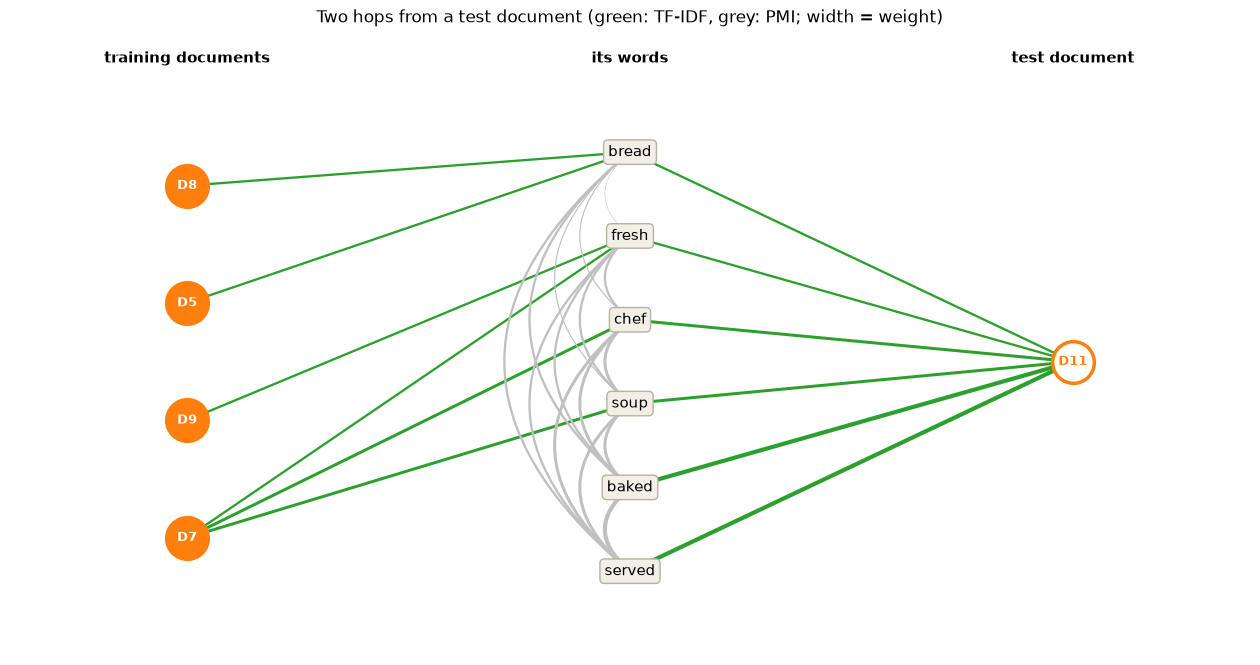

In [ ]:
from matplotlib.patches import FancyArrowPatch

target = n_train + n_words                                    # the first test document, as above
its_words = np.flatnonzero(dense[target])                     # one hop: its words
neighbours = [k for k in range(n_train) if dense[k, its_words].any()]  # two hops: docs sharing a word
sub = [*neighbours, *its_words, target]
sub_names = nodes.name.values[sub]
sub_adj = dense[np.ix_(sub, sub)]

# Three columns: training documents | words | test document.
column = {"train doc": 0, "word": 1, "test doc": 2}
xy_sub = np.zeros((len(sub), 2))
for kind, x in column.items():
    members = [k for k, node in enumerate(sub) if nodes.kind.iloc[node] == kind]
    xy_sub[members] = [(x, y) for y in np.linspace(1, -1, len(members) + 2)[1:-1]]

fig, ax = plt.subplots(figsize=(16, 8))
for i, j in zip(*np.nonzero(np.triu(sub_adj))):
    pmi = nodes.kind.iloc[sub[i]] == nodes.kind.iloc[sub[j]] == "word"
    ax.add_patch(FancyArrowPatch(xy_sub[i], xy_sub[j], arrowstyle="-", zorder=0,
                                 connectionstyle="arc3,rad=0.6" if pmi else "arc3",
                                 color="silver" if pmi else "tab:green", lw=sub_adj[i, j] * 1.2))
for k, node in enumerate(sub):
    if nodes.kind.iloc[node] == "word":
        ax.annotate(nodes.name.iloc[node], xy_sub[k], fontsize=11, ha="center", va="center",
                    bbox=dict(boxstyle="round", fc=WORD_FILL, ec=WORD_EDGE))
    else:
        draw_document(ax, node, xy_sub[k], size=900)
for kind, x in column.items():
    ax.text(x, 1.02, {"train doc": "training documents", "word": "its words",
                      "test doc": "test document"}[kind], ha="center", fontsize=11, weight="bold")
ax.set(xlim=(-0.4, 2.4), ylim=(-1, 1.1))
ax.set_title("Two hops from a test document (green: TF-IDF, grey: PMI; width = weight)", pad=12)
ax.axis("off")

Every path from a training document to the test document goes **through a
word**. A training document that shares three words with it has three paths;
the others have one each. The grey arcs are the PMI edges between the words
themselves.

## The same graph as a matrix

The GCN never sees a drawing. It sees the **adjacency matrix** $A$, where
$A_{ij}$ is the weight of the edge between nodes $i$ and $j$, or zero if there
is none. Rows and columns follow the node order above, so the matrix splits into
blocks:

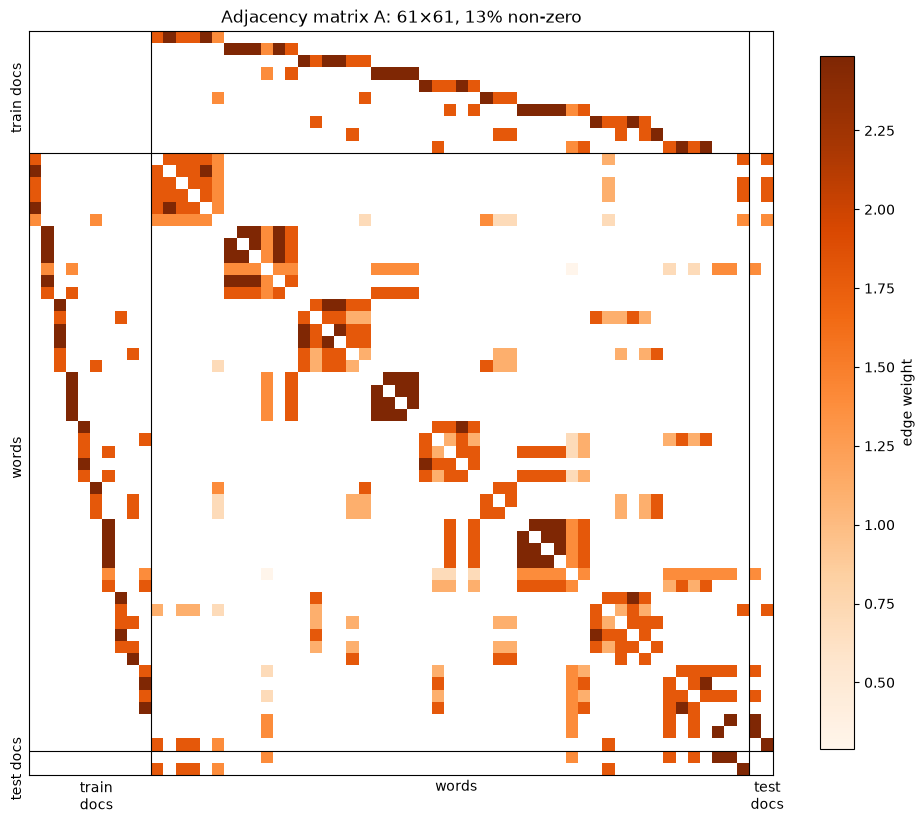

In [32]:
fig, ax = plt.subplots(figsize=(12, 12))
image = ax.imshow(np.ma.masked_equal(dense, 0), cmap="Oranges")    # blank cell = no edge
for border in (n_train - 0.5, n_train + n_words - 0.5):
    ax.axhline(border, color="black", lw=0.8)
    ax.axvline(border, color="black", lw=0.8)
ticks = [n_train / 2, n_train + n_words / 2, n_train + n_words + len(test) / 2]
ax.set_xticks(ticks, ["train\ndocs", "words", "test\ndocs"])
ax.set_yticks(ticks, ["train docs", "words", "test docs"], rotation=90, va="center")
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, shrink=0.75, label="edge weight")
ax.set_title(f"Adjacency matrix A: {len(dense)}×{len(dense)}, "
             f"{np.count_nonzero(dense) / dense.size:.0%} non-zero");

* **words × words**: PMI edges. The vocabulary is listed in order of first
  appearance, so the words of one sentence sit next to each other and form the
  dark squares along the diagonal.
* **documents × words** (and its mirror image, since $A$ is symmetric): TF-IDF
  edges, one per word the document contains.
* **documents × documents**: empty. Documents only meet through words, as the
  zoom showed.
* **The diagonal** is zero. Self-loops are added later, when $A$ is
  normalised.

Even this toy matrix is mostly zeros. In a real corpus almost every entry is
zero, which is why Text4GCN stores $A$ as a `scipy.sparse` matrix.

Here is the zoomed-in neighbourhood as rows and columns of $A$. Read a row to
get a node's edges: the test document's row holds the TF-IDF weights of its
words, and its cells against the training documents are empty.

In [13]:
def show_matrix(matrix: np.ndarray, cmap: str):
    """The sub-matrix of the zoomed-in nodes as a colour-graded table (blank = 0)."""
    return (pd.DataFrame(matrix[np.ix_(sub, sub)], index=sub_names, columns=sub_names)
            .style.background_gradient(cmap=cmap, axis=None)
            .format(lambda v: f"{v:.2f}" if v else ""))

show_matrix(dense, "Oranges")

,cooking doc #8,cooking doc #5,cooking doc #9,cooking doc #7,bread,fresh,chef,soup,baked,served,? doc #11
cooking doc #8,,,,,1.39,,,,,,
cooking doc #5,,,,,1.39,,,,,,
cooking doc #9,,,,,,1.39,,,,,
cooking doc #7,,,,,,1.39,1.79,1.79,,,
bread,1.39,1.39,,,,0.29,0.69,0.69,1.39,1.39,1.39
fresh,,,1.39,1.39,0.29,,1.39,1.39,1.39,1.39,1.39
chef,,,,1.79,0.69,1.39,,1.79,1.79,1.79,1.79
soup,,,,1.79,0.69,1.39,1.79,,1.79,1.79,1.79
baked,,,,,1.39,1.39,1.79,1.79,,2.48,2.48
served,,,,,1.39,1.39,1.79,1.79,2.48,,2.48


## Why this helps: labels travel along edges

A 2-layer GCN computes

$$\hat{A} \cdot \mathrm{ReLU}(\hat{A} \cdot X \cdot W_1) \cdot W_2, \qquad \hat{A} = D^{-1/2} (A + I) \, D^{-1/2}$$

where $X$ holds the node features and $W_1$, $W_2$ are the learned weights.
$\hat{A}$ is the normalised adjacency: self-loops are added ($A + I$), and every
weight is divided by the square root of the weighted degrees $D$ of its two
nodes. Every layer mixes each node with its
neighbours, so after two layers a document has heard from its words *and* from
the other documents that share those words.

The same neighbourhood in $\hat{A}$:

In [ ]:
a_hat = dense + np.eye(len(dense)) # self-loops
d = a_hat.sum(axis=1)
a_hat = a_hat / np.sqrt(np.outer(d, d)) # D^-1/2 (A + I) D^-1/2

show_matrix(a_hat, "Greens")

,cooking doc #8,cooking doc #5,cooking doc #9,cooking doc #7,bread,fresh,chef,soup,baked,served,? doc #11
cooking doc #8,0.07,,,,0.08,,,,,,
cooking doc #5,,0.07,,,0.08,,,,,,
cooking doc #9,,,0.06,,,0.07,,,,,
cooking doc #7,,,,0.07,,0.08,0.11,0.11,,,
bread,0.08,0.08,,,0.05,0.01,0.03,0.03,0.08,0.08,0.08
fresh,,,0.07,0.08,0.01,0.04,0.07,0.07,0.08,0.08,0.08
chef,,,,0.11,0.03,0.07,0.06,0.10,0.12,0.12,0.12
soup,,,,0.11,0.03,0.07,0.10,0.06,0.12,0.12,0.12
baked,,,,,0.08,0.08,0.12,0.12,0.08,0.20,0.20
served,,,,,0.08,0.08,0.12,0.12,0.20,0.08,0.20


Two things changed from $A$. The diagonal is filled, so each node keeps part of its own features at every layer. And the weights shrink, most of all for nodes with many strong edges. *bread* and *fresh* also appear in other documents, so they drop from 1.39 to 0.08. *baked* and *served* appear only here and keep the strongest links to the test document. A well-connected word is a weaker clue about any single document.

We can see the effect without any learning. Spread the one-hot labels of the training documents over two hops ($\hat{A}^2 \cdot Y$) and read the scores of the test documents:

In [15]:
classes = sorted(colors)
y = np.zeros((len(dense), len(classes)))
for k, label in enumerate(train.label):
    y[k, classes.index(label)] = 1.0          # only training documents carry a label

scores = a_hat @ a_hat @ y                    # two hops of propagation
test_rows = range(n_train + n_words, len(dense))
pd.DataFrame(scores[test_rows], columns=classes,
             index=[f"{lb} (true)" for lb in test.label]).round(3)

,cooking,space
cooking (true),0.052,0.000
space (true),0.000,0.082


Each test document gets the higher score for its true topic. The
labels reached it through the graph.

A GCN learns *how much* each hop and each feature should count, instead of
using fixed weights. Because test documents are nodes of the same graph, the
model is **transductive**: classifying a new document means adding it to the
graph and training again.

**Next:** [2 · Your first classifier](https://vitormeriat.github.io/text4gcn/tutorials/02_first_classifier/) runs the same three steps on a real
benchmark and trains the GCN.